**Import libraries**

In [2]:
import agentpy as ap
import networkx as nx 
import random 
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt
from sklearn import preprocessing

**Data and functions useful for the model**

In [4]:
def sigmoid(x):
  return 1 / (1 + math.exp(-x))

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

levels = np.array([1, 2, 3, 4, 5])
probs  = np.array([0.183, 0.281, 0.244, 0.159, 0.134]) #INVALSI report, page 92.
mean = np.average(levels, weights=probs)
std  = np.sqrt(np.average((levels - mean)**2, weights=probs))

print(f"Mean: {mean:.3f}, Std: {std:.3f}")


Mean: 2.780, Std: 1.288


In [6]:
Exercises=pd.read_csv('Exercises_abilities.csv', sep=';')

Exercises=Exercises.sort_values(by='Exercise')
Exercises.columns

Index(['Exercise', 'Maths_knowledge', 'Physics_knowledge', 'Problem_solving',
       'Total', 'AI_Maths_knowledge', 'AI_Physics_knowledge',
       'AI_Problem_solving', 'AI_total'],
      dtype='object')

In [7]:
#print(Exercises)

In [8]:
# Exercises[Exercises['AI_total']==1]
# min(Exercises['AI_total'])
# min(Exercises['Total'])
# Exercises

In [9]:
# Normalization of scores between 0 and 0.5 to make sense in the model 

lower=0
upper=0.5
data_min=min(Exercises['Total'])
data_max=max(Exercises['Total'])

Exercises_norm=Exercises.copy()

# Normalization of total
Exercises_norm['Total']=lower + (upper - lower) * (Exercises['Total'] - data_min) / (data_max - data_min)

# Other columns normalized with the same scale such that total is still the sum
scale=Exercises_norm['Total'] / Exercises['Total']
Exercises_norm['Maths_knowledge']=Exercises['Maths_knowledge'] * scale
Exercises_norm['Physics_knowledge']=Exercises['Physics_knowledge'] * scale
Exercises_norm['Problem_solving']=Exercises['Problem_solving'] * scale
Exercises_norm['AI_Maths_knowledge']=Exercises['AI_Maths_knowledge'] * scale
Exercises_norm['AI_Physics_knowledge']=Exercises['AI_Physics_knowledge'] * scale
Exercises_norm['AI_Problem_solving']=Exercises['AI_Problem_solving'] * scale
Exercises_norm['AI_total']=Exercises['AI_total'] * scale

In [10]:
#Exercises_norm

**Model**

In [12]:
maths_knowledge=Exercises_norm['Maths_knowledge'].to_list()
physics_knowledge=Exercises_norm['Physics_knowledge'].to_list()
problem_solving=Exercises_norm['Problem_solving'].to_list()

maths_knowledge_AI=Exercises_norm['AI_Maths_knowledge'].to_list()
physics_knowledge_AI=Exercises_norm['AI_Physics_knowledge'].to_list()
problem_solving_AI=Exercises_norm['AI_Problem_solving'].to_list()

In [13]:
#maths_knowledge

In [14]:
#physics_knowledge

In [15]:
#problem_solving

In [16]:
#maths_knowledge_AI

In [17]:
#physics_knowledge_AI

In [18]:
#problem_solving_AI

In [19]:
# Definition of the agents, with their features and behaviours
class Student(ap.Agent):
    
    def setup(self):  

        #Competence initialization --> FROM DATA
        mu=195.9 #INVALSI report, page 92.
        sigma=1.288
        self.competence=np.random.normal(mu, scale=sigma)
        self.competence_start=self.competence
        self.additional_competence=0
        self.competence_old = self.competence

        #AI dependence initialization --> We can vary it
        self.AI_dependence=0.5 #Let's assume that everyone has a 50% prob to be dependent on AI

        #Reliance on friends initialization --> We can vary it
        self.reliance_on_friends=0.5 #np.random.uniform(0,1) # Quanto tendi ad affidarti agli amici
        self.dice=0

        #Strategies: Not using AI=0, Using AI=1
        self.strategy=0
        
        # If you solve or not the excercise
        self.success=0

        #To save data
        self.record(['competence','AI_dependence', 'reliance_on_friends', 'strategy', 'success', 'dice', 'competence_start', 'additional_competence'])


    def Choose_strategy(self):
        
        # comment probability  = 0 if you want to let the agents use AI, comment probability = sigmois(...) otherwise
        '''probability = sigmoid(self.p.competencies*(maths_knowledge[self.model.t]
                                          +physics_knowledge[self.model.t]
                                          +problem_solving[self.model.t]-self.additional_competence)
                                          +self.p.AI*self.AI_dependence
                                          -self.p.friends*self.reliance_on_friends)
        '''
                                          
        probability = 0

        #Choose strategy
        self.strategy=random.choices([1,0], cum_weights = (probability,1))[0] #strategy 1 (use AI) is chosen with prob. given by probability computed 
                                                                              #using the sigmoid

    def Interact_with_friends(self):

        possible_competence_gain=random.uniform(0,1-(maths_knowledge[self.model.t]+physics_knowledge[self.model.t]
                + problem_solving[self.model.t]))  #not used in the model
        if (self.strategy==0):  #if agent not use AI choose to interact with froends (2) or to not interact (3). 
                                #Each agent chhose to inteacr with friends (2) with probability given by reliance_on_friends.
            self.dice=random.choices([2,3], cum_weights = (self.reliance_on_friends,1))[0] #2=interact with friends, 3=don't interact with friends
            if (self.dice==2):
            #if self.dice == 3:
                neighbours = list(self.model.network.neighbors(self))
                if len(neighbours) == 0:
                    self.dice = 3
                else:
                    helper_with_homework=random.choice(neighbours)
                    if self.competence < helper_with_homework.competence: 
                        self.competence = random.uniform(self.competence,helper_with_homework.competence)
                        #self.competence = self.competence + 0.1

    
    def Update_reliance_on_friends(self):
        if self.reliance_on_friends < 0.5:
            reliance_growth=random.uniform(self.reliance_on_friends,1-(self.reliance_on_friends))
        elif self.reliance_on_friends > 0.5:
            reliance_growth=random.uniform(1-(self.reliance_on_friends),(self.reliance_on_friends))
        else:
            reliance_growth=random.uniform(0,0.5)

        #EXAMPLE - We can discuss about changing the update
        if (self.dice==2):
            if (self.competence>self.competence_start):
                self.reliance_on_friends = min(1,self.reliance_on_friends+reliance_growth)
            elif(self.competence<self.competence_start):
                self.reliance_on_friends=max(0,self.reliance_on_friends-reliance_growth)

    def Exercises_results(self):
        #here we decide if the exercise is successfully solved or not
        if self.strategy==0:   #people not using AI (strategy=0) solve the exercise successfully (0 = success) with probability success_rate = 0.54
            self.success=random.choices([0,1], cum_weights=(self.p.success_rate,1))[0] #0=success, 1=not success
        else:    #people using AI (strategy=1) solve the exercise successfully (0 = success) with probability success_rate - 0.17 = 0.37
            self.success=random.choices([0,1], cum_weights=(self.p.success_rate-0.17,1))[0] #0=success, 1=not success --> -0.17 From paper
                                    #we can keep the probability to success = success_rate = 0.54 also for agents using AI at the beginning
            

    def Update_competencies(self):
        t = self.model.t #t current time step t
        # Normalized values of the current exercise
        km, kp, ps = maths_knowledge[t], physics_knowledge[t], problem_solving[t]
        km_ai, kp_ai, ps_ai = maths_knowledge_AI[t], physics_knowledge_AI[t], problem_solving_AI[t]

        peer = (self.dice == 2)  # True if the agent interacted with friends
        # Average of competencies of neighbors at time t 
        neighbours = list(self.model.network.neighbors(self)) #list of neighbors
        #to compute the average of the neighbors we need to save the competencies of the agents in a variable competence_old
        avg_neigh = (sum(n.competence_old for n in neighbours) / len(neighbours) if neighbours else self.competence_old)

        #sigma = self.p.sigma
        sigma = self.reliance_on_friends  #sigma is the relience on friends, the more an agent relies on peers the more consider their competencies

        AI_growth=random.uniform(self.AI_dependence,1-(self.AI_dependence))
        
        if self.strategy == 0:                 # agents not using AI
            if self.success == 0:              # success in the exercise (0 = success)
                if not peer:                   # not interact with friends
                    self.competence = self.competence + km + kp + ps
                else:                          # interact with friends
                    #self.competence = (1 - sigma) * self.competence + sigma * avg_neigh + km + kp + ps
                    self.competence +=  km + kp + ps
                    
                self.AI_dependence=max(0,self.AI_dependence-AI_growth)
            else:                              # not success in the exercise (1 = not success)
                if not peer:                   # not interact with friends
                    self.competence = self.competence             
                else:                          # interact with friends
                    #self.competence = (1 - sigma) * self.competence + sigma * avg_neigh
                    self.competence
                
        else:                                  # agents using AI
            #self.competence = (self.competence + random.uniform(0, km_ai) + random.uniform(0, kp_ai) + random.uniform(-ps_ai, 0))
            #self.competence = self.competence + km_ai + kp_ai - ps_ai
            self.competence = (self.competence + random.uniform(0, km_ai) + random.uniform(0, kp_ai) -ps_ai)
            self.AI_dependence=min(1,self.AI_dependence+AI_growth)

            # Implementation of the case where agents can use AI actively/correctly or not
            #active = random.choices([True, False], cum_weights=(self.p.active_AI, 1))[0]
            #if active:                         # la usa attivamente: impara dall'esercizio
            #    self.competence = self.competence + km_ai + kp_ai + ps_ai
            #else:                              # copia e basta: competenza ferma
            #    self.competence = self.competence
            
        # self.additional_competence = self.competence - self.competence_start
        self.additional_competence = -0.5+ (1.5/15.52)*(self.competence - self.competence_start+2.36)
        # print(self.additional_competence)
        self.record(['competence','AI_dependence', 'reliance_on_friends', 'strategy', 'success', 'dice', 'competence_start', 'additional_competence'])
        # self.competence_start=self.competence

In [20]:
# Creation of the network and managing of the behaviours
class Classroom(ap.Model):
    
    def setup(self):
        
        #Create agents and network
        self.students = ap.AgentList(self, self.p.population, Student)
        #self.network = self.students.network = ap.Network(self, nx.watts_strogatz_graph(30,4, p=0.1)) #SW
        #self.network = self.students.network = ap.Network(self, nx.erdos_renyi_graph(30, 4/29)) #Erdos-Renyi: N=30, mean degree 4 (p = <k>/(n-1) = 4/29)
        self.network = self.students.network = ap.Network(self, nx.stochastic_block_model([6]*5, [[0.7 if i==j else 0.02 for j in range(5)] for i in range(5)])) #SBM: 5 blocks of 6, p_in=0.47, p_out=0.06
        #G = self.network.graph
        #print(f"Mean degree = {2*G.number_of_edges()/G.number_of_nodes():.2f}  (target 4)")
        
        ## DECOMMENT FOR ALL THE NWTEORK STRUCTURE APART FROM SBMM
        #self.network.add_agents(self.students, self.network.nodes)
        ## DECOMMENT FOR STOCHASTIC BLOCK MODEL MODIFIED
        sorted_students = ap.AgentList(self, sorted(self.students, key=lambda a: a.competence))
        self.network.add_agents(sorted_students, self.network.nodes)
        
        # CONTROLLO BLOCCHI PER UN CONTROLLO
        #G = self.network.graph
        #for b in range(5):
        #    comps = sorted(a.competence for a in sorted_students
        #                   if G.nodes[self.network.positions[a]]['block'] == b)
        #    print(f"Blocco {b}: n={len(comps)}  competenze = {[round(c, 2) for c in comps]}")
        #print(f"Grado medio = {2*G.number_of_edges()/G.number_of_nodes():.2f}")
             
    def update(self):    
        #To record the fraction of students using AI and not using it at each time-step 
        for i, c in enumerate(('No AI', 'Yes AI')):
            n_students = len(self.students.select(self.students.strategy == i))
            self[c] = n_students / self.p.population 
            self.record(c)

        #  debug 
        #comps = list(self.students.competence)
        #print(f"t={self.t:2d} | usano AI: {self['Yes AI']:.0%} | "f"competenza media={np.mean(comps):.3f} "f"(min={min(comps):.3f}, max={max(comps):.3f})")

    # Order of strategies --> doubt about where to update reliance on friends
    def step(self):    

        self.students.Choose_strategy()
        self.students.Interact_with_friends()
        self.students.Exercises_results()
        self.students.Update_competencies()
        self.students.Update_reliance_on_friends()

In [21]:
# One run
parameters = {  
    'seed': 42,
    'population': 30, # Average size of a class

    # 'maths': 0.3,
    # 'physics': 0.3,
    # 'ps': 0.3,     --> Possible parameters we'd like to add

    'competencies': 0.33,
    'AI':0.33,
    'friends': 0.33, # --> Parameters appearing in the sigmoid: here we assume equal weight for all the components

    'success_rate':0.54, # From INVALSI report 2025

    'steps': 60  # Number of excercises, 
    #'active_AI': 0.5,   # prob. che chi usa l'AI la usi attivamente (imparando)
}

model = Classroom(parameters)
results = model.run(steps=model.p.steps) 

Completed: 60 steps
Run time: 0:00:00.018383
Simulation finished


In [22]:
results

DataDict {
'info': Dictionary with 9 keys
'parameters': 
    'constants': Dictionary with 7 keys
'variables': 
    'Student': DataFrame with 8 variables and 1830 rows
    'Classroom': DataFrame with 2 variables and 61 rows
'reporters': DataFrame with 1 variable and 1 row
}

In [23]:
# Multiple runs
parameters = {  
    'seed': 42,
    'population': 30, # Average size of a class

    # 'maths': 0.3,
    # 'physics': 0.3,
    # 'ps': 0.3,     --> Possible parameters we'd like to add

    'competencies': 0.33,
    'AI':0.33,
    'friends': 0.33, # --> Parameters appearing in the sigmoid: here we assume equal weight for all the components

    'success_rate':0.54, # From INVALSI report 2025

    'steps':60  # Number of excercises
    #'active_AI': 0.5,   # prob. che chi usa l'AI la usi attivamente (imparando)
}


# Sample con parametri fissi: ap.sample senza range genera una sola combinazione
sample = ap.Sample(parameters, n=1)

# iterations = numero di ripetizioni con la stessa combinazione di parametri
exp = ap.Experiment(Classroom, sample, iterations=1000, record=True)
results_multiple = exp.run()

# I risultati aggregati per run
print(results_multiple.variables.Student)

Scheduled runs: 1000
Completed: 1000, estimated time remaining: 0:00:00
Experiment finished
Run time: 0:00:17.652302
                     competence  AI_dependence  reliance_on_friends  strategy  \
iteration obj_id t                                                              
0         1      0   196.334124            0.5             0.500000         0   
                 1   196.456695            0.0             0.500000         0   
                 2   196.606767            0.0             0.701338         0   
                 3   196.678141            0.0             1.000000         0   
                 4   196.678141            0.0             1.000000         0   
...                         ...            ...                  ...       ...   
999       30     56  205.937857            0.0             1.000000         0   
                 57  206.301978            0.0             1.000000         0   
                 58  206.457150            0.0             1.000000      

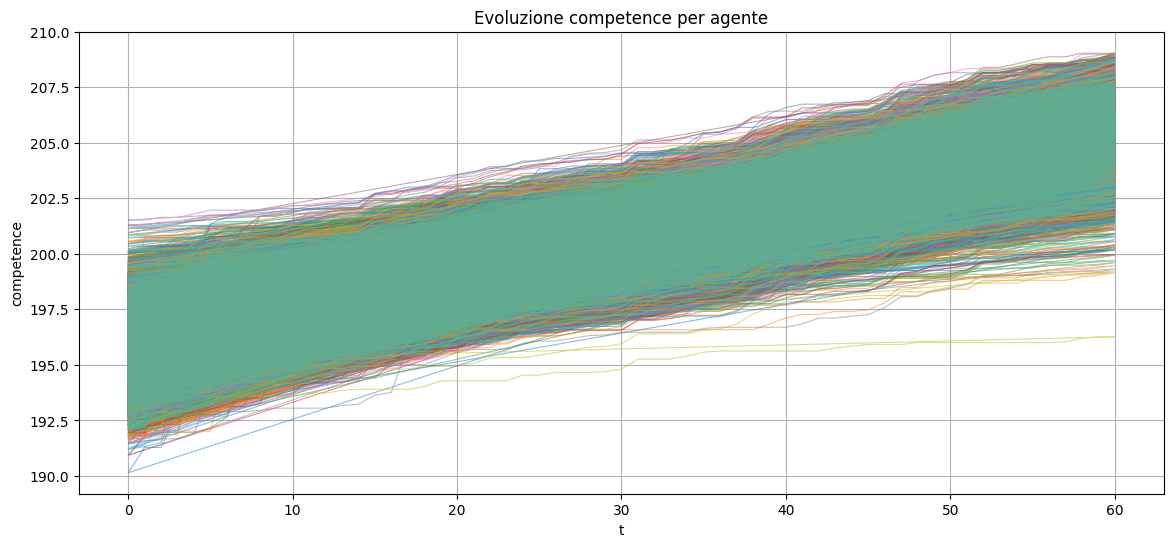

In [24]:
df_multiple_iterations=results_multiple.variables.Student
fig, ax = plt.subplots(figsize=(14, 6))

for obj_id, group in df_multiple_iterations.groupby(level='obj_id'):
    ax.plot(group.index.get_level_values('t'), group['competence'], alpha=0.5, linewidth=0.8)

ax.set_xlabel('t')
ax.set_ylabel('competence')
ax.set_title('Evoluzione competence per agente')
ax.grid(True)
plt.show()

In [25]:
df1=df_multiple_iterations.groupby(level='obj_id').get_group(1)

In [26]:
df_iterations = results_multiple.variables.Student.reset_index()

# Crea un ID univoco per ogni agente-iterazione
df_iterations['unique_id'] = df_iterations['iteration'].astype(str) + '_' + df_iterations['obj_id'].astype(str)


# Ora ogni traiettoria è separata
for uid, group in df_iterations.groupby('unique_id'):
    # plt.plot(group['t'], group['competence'], alpha=0.3, color='steelblue', linewidth=0.8)
    if (uid=='0_1'):
        print(group['competence'][60])
competenze_finali=[]
for uid, group in df_iterations.groupby('unique_id'):
    group = group.set_index('t').sort_index()
    competenze_finali.append(group.loc[60, 'competence'])

205.46552723925086


In [27]:
df_iterations

,iteration,obj_id,t,competence,AI_dependence,reliance_on_friends,strategy,success,dice,competence_start,additional_competence,unique_id
0,0,1,0,196.334124,0.5,0.500000,0,0,0,196.334124,0.000000,0_1
1,0,1,1,196.456695,0.0,0.500000,0,0,2,196.334124,-0.260061,0_1
2,0,1,2,196.606767,0.0,0.701338,0,0,2,196.334124,-0.245556,0_1
3,0,1,3,196.678141,0.0,1.000000,0,0,2,196.334124,-0.238658,0_1
4,0,1,4,196.678141,0.0,1.000000,0,1,2,196.334124,-0.238658,0_1
...,...,...,...,...,...,...,...,...,...,...,...,...
1829995,999,30,56,205.937857,0.0,1.000000,0,0,2,194.899870,0.794908,999_30
1829996,999,30,57,206.301978,0.0,1.000000,0,0,2,194.899870,0.830101,999_30
1829997,999,30,58,206.457150,0.0,1.000000,0,0,2,194.899870,0.845098,999_30
1829998,999,30,59,206.457150,0.0,1.000000,0,1,2,194.899870,0.845098,999_30


In [28]:
df_iterations['additional_competence'].max()

1.2396962301018744

In [29]:
df_iterations['additional_competence'].min()

-0.2719072164948454

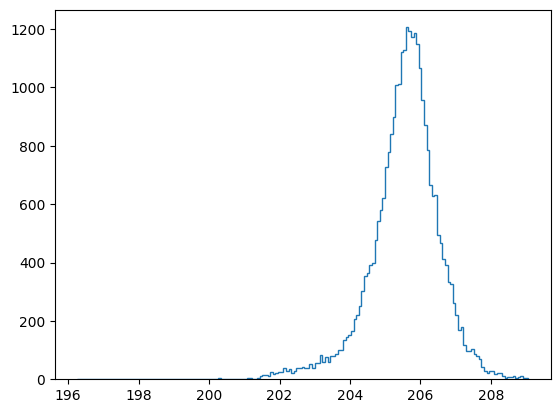

In [30]:
# np.sqrt(len(competenze_finali))
counts, bins = np.histogram(competenze_finali, bins=int(np.sqrt(len(competenze_finali))))
plt.stairs(counts, bins)
plt.show()

In [31]:
# Save the results as a csv
df_students_output = results_multiple.variables.Student.reset_index()
df_students_output.to_csv("students_output_SBM_modified_noAI.csv", index=False)

**Analysis**

In [33]:
#Code to access the generated data

# One simulation
df_classroom=results.variables.Classroom

df_students=results.variables.Student

# Multiple simulations
df_multiple_iterations=results_multiple.variables.Student

df_students

competence  AI_dependence  reliance_on_friends  strategy  success  \
obj_id t                                                                       
1      0   196.921304            0.5             0.500000         0        0   
       1   197.041994            0.0             0.500000         0        0   
       2   197.041994            0.0             0.610225         0        1   
       3   197.041994            0.0             1.000000         0        1   
       4   197.197166            0.0             1.000000         0        0   
...               ...            ...                  ...       ...      ...   
30     56  203.706743            0.0             1.000000         0        0   
       57  203.741226            0.0             1.000000         0        0   
       58  204.032561            0.0             1.000000         0        0   
       59  204.033719            0.0             1.000000         0        1   
       60  204.154409            0.0             1.000000         0        0   

           dice  competence_start  additional_competence  
obj_id t                                                  
1      0      0        196.921304               0.000000  
       1      2        196.921304              -0.260243  
       2      2        196.921304              -0.260243  
       3      2        196.921304              -0.260243  
       4      2        196.921304              -0.245245  
...         ...               ...                    ...  
30     56     2        196.401179               0.434172  
       57     2        196.401179               0.437505  
       58     2        196.401179               0.465662  
       59     2        196.401179               0.465774  
       60     2        196.401179               0.477438  

[1830 rows x 8 columns]

In [34]:
df_multiple_iterations

competence  AI_dependence  reliance_on_friends  strategy  \
iteration obj_id t                                                              
0         1      0   196.334124            0.5             0.500000         0   
                 1   196.456695            0.0             0.500000         0   
                 2   196.606767            0.0             0.701338         0   
                 3   196.678141            0.0             1.000000         0   
                 4   196.678141            0.0             1.000000         0   
...                         ...            ...                  ...       ...   
999       30     56  205.937857            0.0             1.000000         0   
                 57  206.301978            0.0             1.000000         0   
                 58  206.457150            0.0             1.000000         0   
                 59  206.457150            0.0             1.000000         0   
                 60  206.601663            0.0             1.000000         0   

                     success  dice  competence_start  additional_competence  
iteration obj_id t                                                           
0         1      0         0     0        196.334124               0.000000  
                 1         0     2        196.334124              -0.260061  
                 2         0     2        196.334124              -0.245556  
                 3         0     2        196.334124              -0.238658  
                 4         1     2        196.334124              -0.238658  
...                      ...   ...               ...                    ...  
999       30     56        0     2        194.899870               0.794908  
                 57        0     2        194.899870               0.830101  
                 58        0     2        194.899870               0.845098  
                 59        1     2        194.899870               0.845098  
                 60        1     2        194.899870               0.859065  

[1830000 rows x 8 columns]

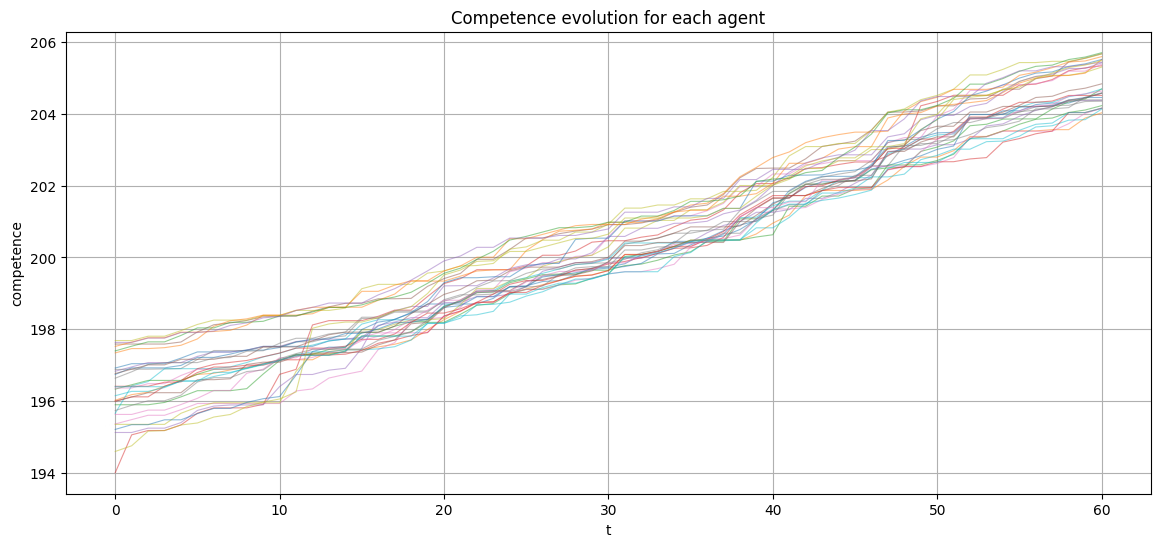

In [35]:
fig, ax = plt.subplots(figsize=(14, 6))

for obj_id, group in df_students.groupby(level='obj_id'):
    ax.plot(group.index.get_level_values('t'), group['competence'], alpha=0.5, linewidth=0.8)

ax.set_xlabel('t')
ax.set_ylabel('competence')
ax.set_title('Competence evolution for each agent')
ax.grid(True)
plt.show()

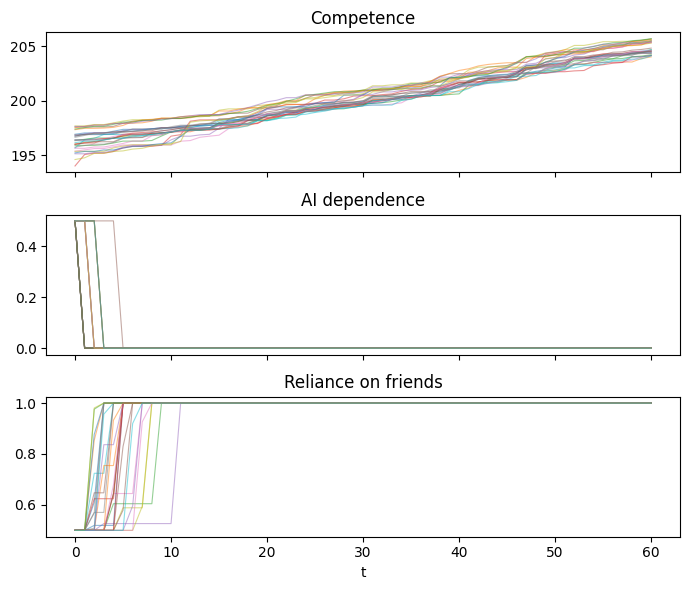

In [36]:
fig, axes = plt.subplots(3, 1, figsize=(7, 6), sharex=True)

for obj_id, group in df_students.groupby(level='obj_id'):
    axes[0].plot(group.index.get_level_values('t'), group['competence'], alpha=0.5, linewidth=0.8)
    axes[0].set_title('Competence')

for obj_id, group in df_students.groupby(level='obj_id'):
    axes[1].plot(group.index.get_level_values('t'), group['AI_dependence'], alpha=0.5, linewidth=0.8)
    axes[1].set_title('AI dependence')

for obj_id, group in df_students.groupby(level='obj_id'):
    axes[2].plot(group.index.get_level_values('t'), group['reliance_on_friends'], alpha=0.5, linewidth=0.8)
    axes[2].set_title('Reliance on friends')

axes[-1].set_xlabel('t')
plt.tight_layout()
plt.show()